<a href="https://www.kaggle.com/code/shravansirra/aan-case-study?scriptVersionId=355856949" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

Import Libraries


In [1]:
import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# Check GPU

In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("GPU is available")
    for gpu in gpus:
        print(gpu)
else:
    print("GPU is not available")

GPU is available
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')


# Download Dataset

In [3]:
import kagglehub

path = kagglehub.dataset_download(
    "kaanerkez/waste-classfication-dataset"
)

print("Dataset path:", path)

Dataset path: /kaggle/input/datasets/kaanerkez/waste-classfication-dataset


# Inspect Dataset Structure

In [4]:
for root, dirs, files in os.walk(path):
    image_count = sum(
        file.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
        for file in files
    )

    if image_count > 0:
        print(root, "->", image_count, "images")

/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/metal -> 400 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/glass -> 400 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/organic -> 400 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/PCB -> 398 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/Television -> 398 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/Microwave -> 399 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/paper -> 400 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/Mouse -> 399 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images/Battery -> 398 images
/kaggle/input/datasets/kaanerkez/waste-classfication-dataset/b

# Set Dataset Directory


In [5]:
dataset_dir = path

items = os.listdir(dataset_dir)

if len(items) == 1 and os.path.isdir(os.path.join(dataset_dir, items[0])):
    dataset_dir = os.path.join(dataset_dir, items[0])

print("Dataset directory:", dataset_dir)
print("Folders:", os.listdir(dataset_dir))

Dataset directory: /kaggle/input/datasets/kaanerkez/waste-classfication-dataset/balanced_waste_images
Folders: ['metal', 'glass', 'organic', 'PCB', 'Television', 'Microwave', 'paper', 'Mouse', 'Battery', 'Washing Machine', 'Mobile', 'trash', 'Keyboard', 'cardboard', 'Player', 'plastic', 'Printer']


# Create Image DataFrame

In [6]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

records = []

for class_name in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_name)

    if os.path.isdir(class_path):
        for root, dirs, files in os.walk(class_path):
            for file in files:
                if file.lower().endswith(image_extensions):
                    records.append({
                        "filepath": os.path.join(root, file),
                        "class": class_name
                    })

df = pd.DataFrame(records)

print("Total Images:", len(df))
print("Number of Classes:", df["class"].nunique())
print("\nClasses:")
print(sorted(df["class"].unique()))

Total Images: 6782
Number of Classes: 17

Classes:
['Battery', 'Keyboard', 'Microwave', 'Mobile', 'Mouse', 'PCB', 'Player', 'Printer', 'Television', 'Washing Machine', 'cardboard', 'glass', 'metal', 'organic', 'paper', 'plastic', 'trash']


# Dataset Class Distribution

class
Battery            398
Keyboard           399
Microwave          399
Mobile             400
Mouse              399
PCB                398
Player             399
Printer            395
Television         398
Washing Machine    400
cardboard          400
glass              400
metal              400
organic            400
paper              400
plastic            400
trash              397
Name: count, dtype: int64


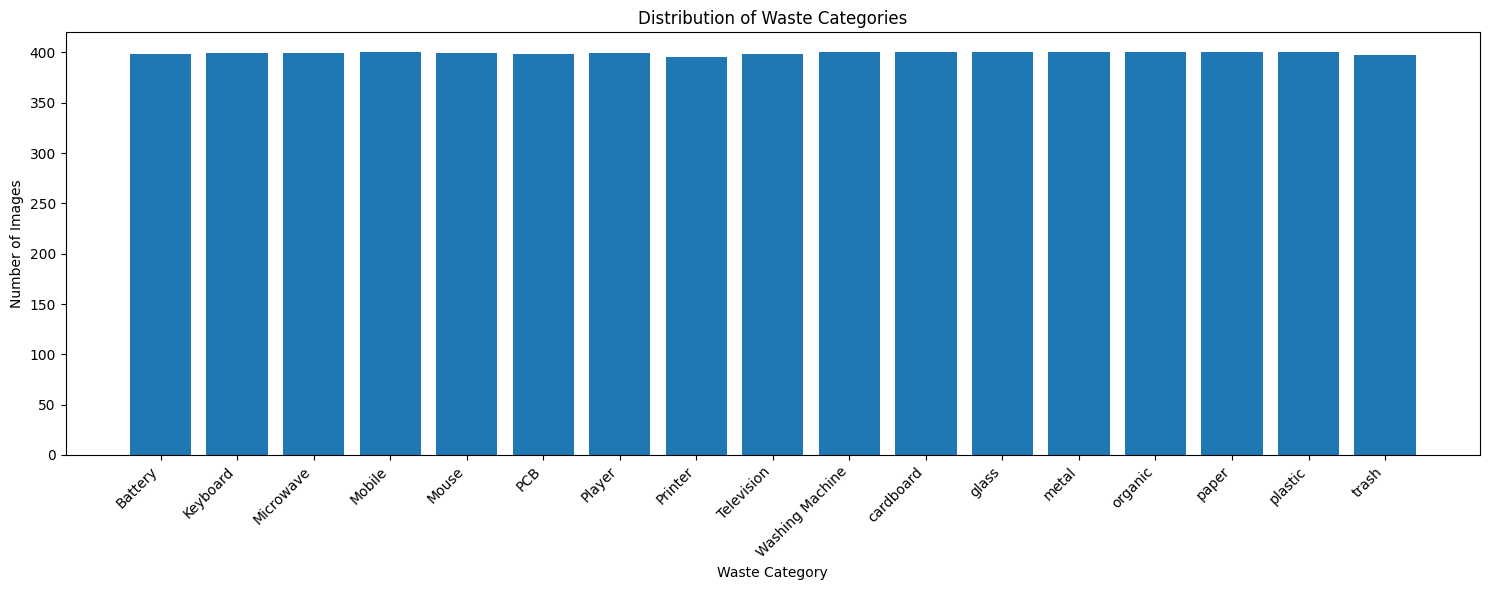

In [7]:
class_counts = df["class"].value_counts().sort_index()

print(class_counts)

plt.figure(figsize=(15, 6))

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Distribution of Waste Categories")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

# Display One Image From Every Class

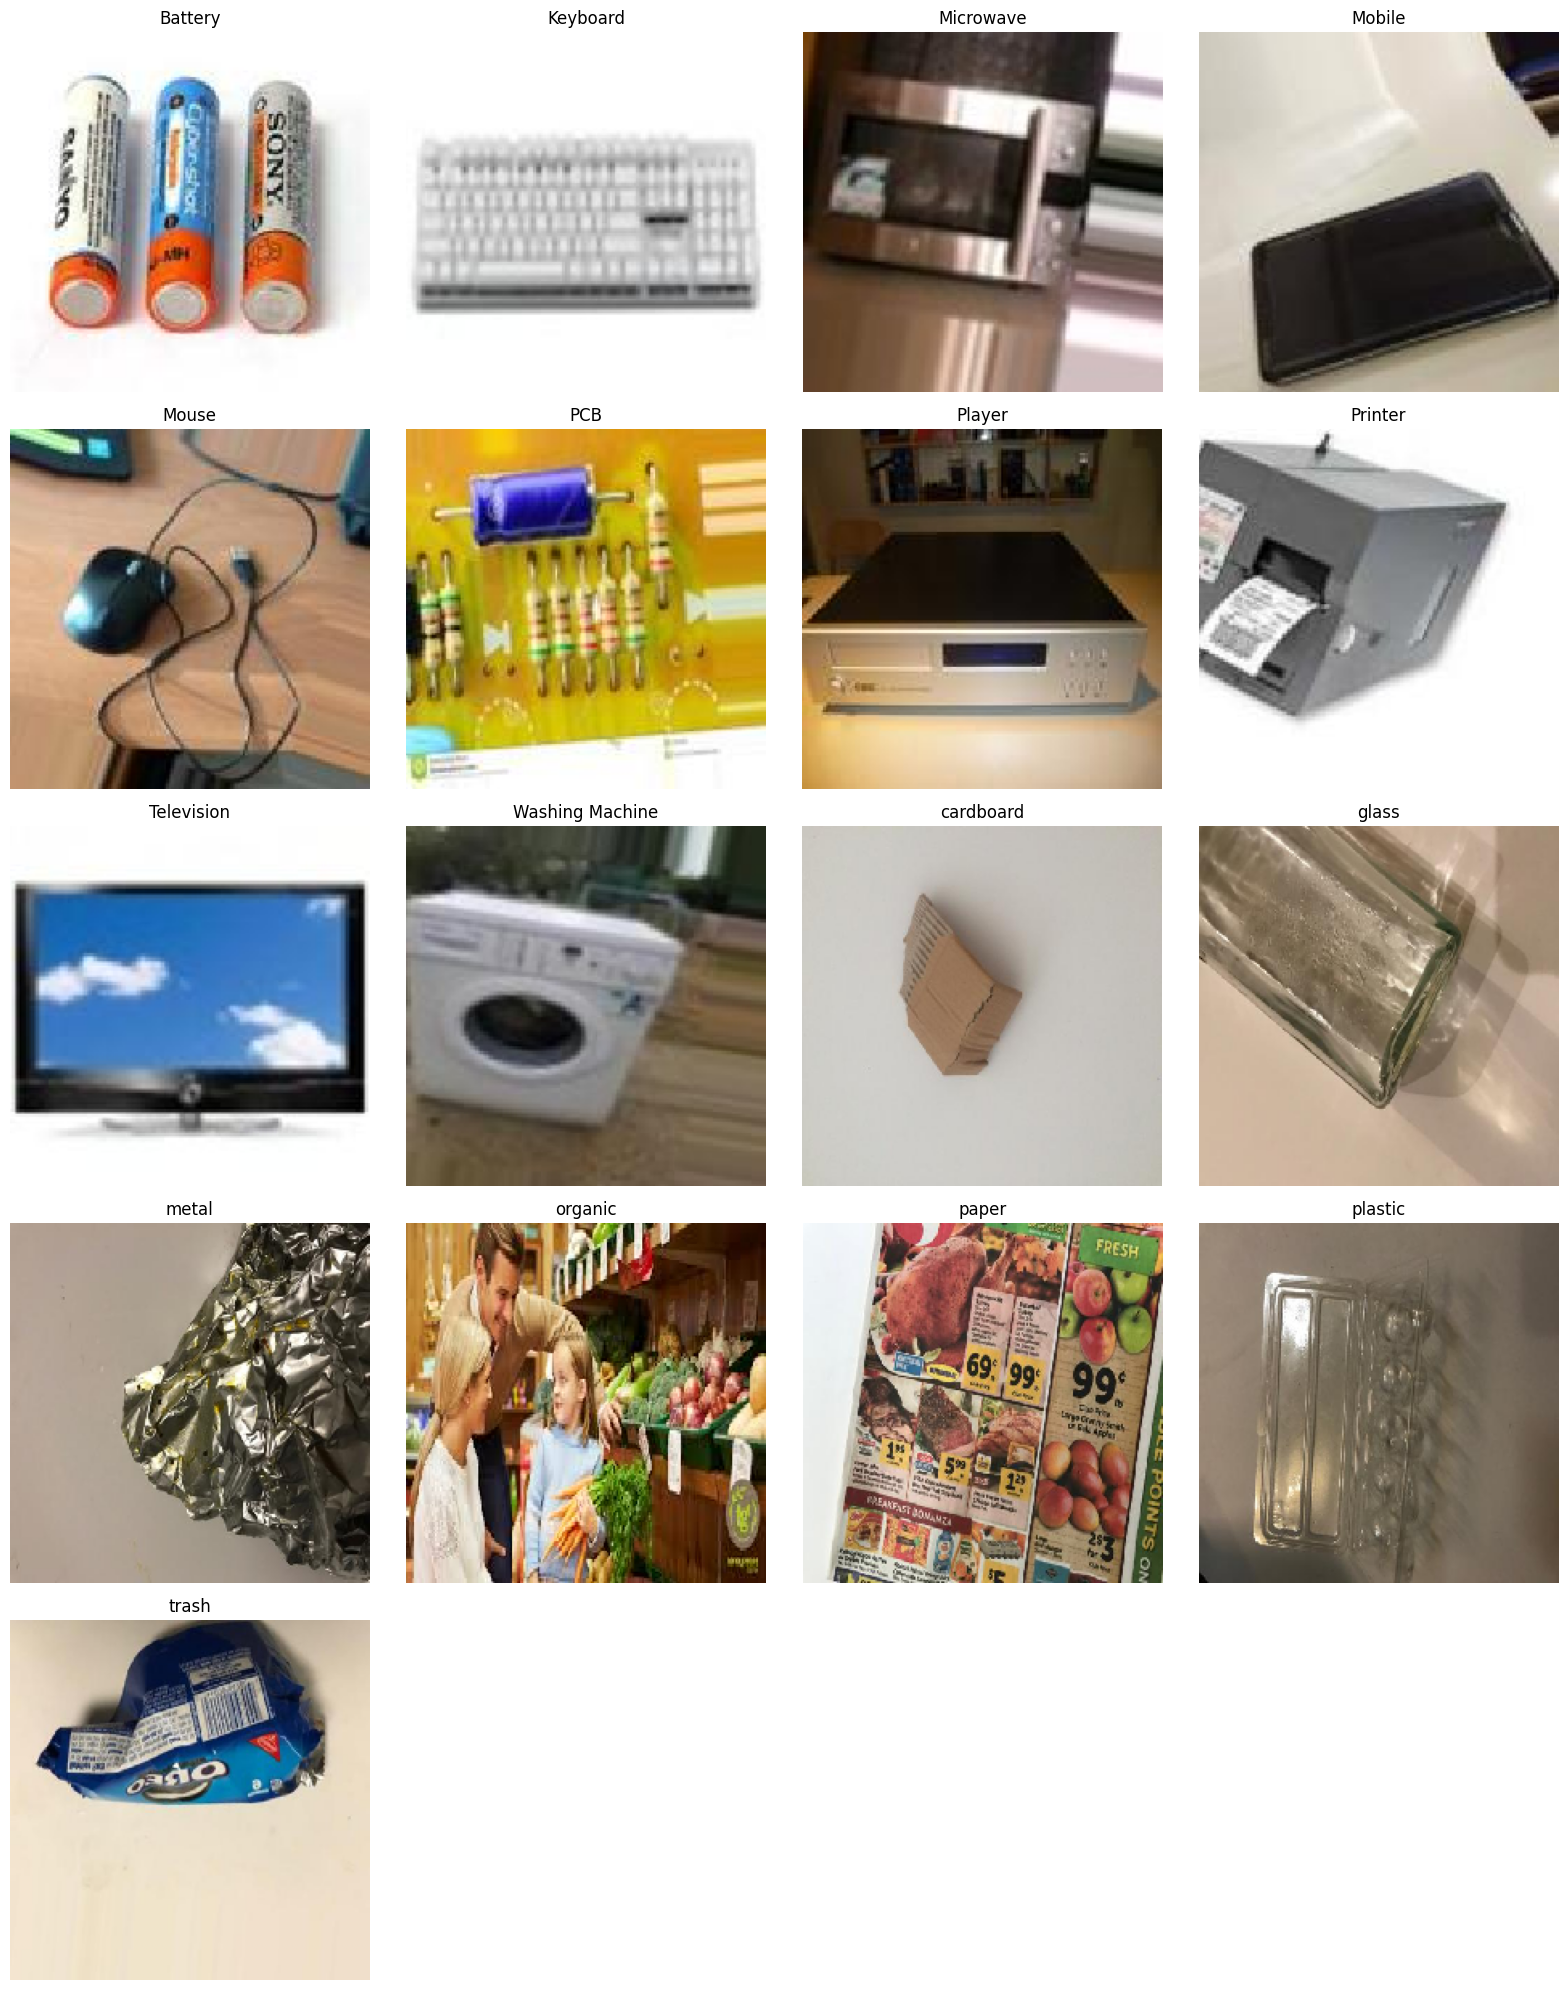

In [8]:
classes = sorted(df["class"].unique())

cols = 4
rows = math.ceil(len(classes) / cols)

plt.figure(figsize=(16, rows * 4))

for i, class_name in enumerate(classes):

    sample = df[
        df["class"] == class_name
    ].sample(
        1,
        random_state=42
    ).iloc[0]

    image = tf.keras.utils.load_img(
        sample["filepath"],
        target_size=(224, 224)
    )

    image = tf.keras.utils.img_to_array(image)

    plt.subplot(
        rows,
        cols,
        i + 1
    )

    plt.imshow(
        image.astype("uint8")
    )

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Check Image Dimensions

In [9]:
dimensions = []

sample_df = df.sample(
    min(1000, len(df)),
    random_state=42
)

for filepath in sample_df["filepath"]:

    try:
        image = tf.keras.utils.load_img(filepath)
        dimensions.append(image.size)

    except:
        pass

dimensions_df = pd.DataFrame(
    dimensions,
    columns=["width", "height"]
)

print(dimensions_df.describe())

             width       height
count  1000.000000  1000.000000
mean    284.225000   234.371000
std     169.543131   110.226972
min     150.000000   142.000000
25%     150.000000   150.000000
50%     150.000000   150.000000
75%     512.000000   384.000000
max     512.000000   384.000000


# Visualize Image Dimensions

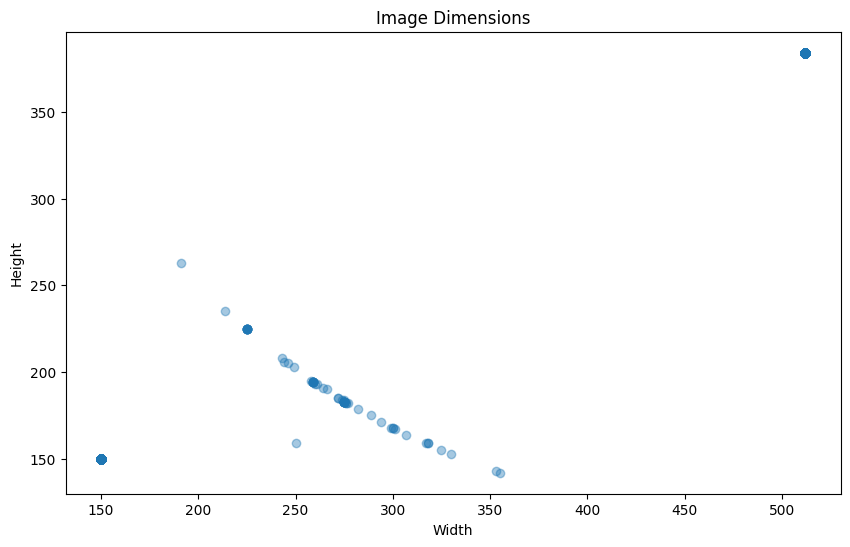

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    dimensions_df["width"],
    dimensions_df["height"],
    alpha=0.4
)

plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Dimensions")

plt.show()

# Check Corrupted Images

In [11]:
valid_records = []
invalid_count = 0

for _, row in df.iterrows():
    try:
        image = tf.keras.utils.load_img(row["filepath"])
        valid_records.append(row)
    except Exception:
        invalid_count += 1
        print("Invalid image:", row["filepath"])

df = pd.DataFrame(valid_records).reset_index(drop=True)

print("Valid Images:", len(df))
print("Invalid Images:", invalid_count)

Valid Images: 6782
Invalid Images: 0


# Final Dataset Information

In [12]:
print("Total Images:", len(df))
print("Total Classes:", df["class"].nunique())
print("\nClass Names:")

for i, class_name in enumerate(
    sorted(df["class"].unique())
):
    print(i, "->", class_name)

Total Images: 6782
Total Classes: 17

Class Names:
0 -> Battery
1 -> Keyboard
2 -> Microwave
3 -> Mobile
4 -> Mouse
5 -> PCB
6 -> Player
7 -> Printer
8 -> Television
9 -> Washing Machine
10 -> cardboard
11 -> glass
12 -> metal
13 -> organic
14 -> paper
15 -> plastic
16 -> trash


# Train / Validation / Test Split

In [13]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=42
)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

Training Images: 4747
Validation Images: 1017
Testing Images: 1018


# Verify Split

In [14]:
split_distribution = pd.DataFrame({
    "Train": train_df["class"].value_counts(),
    "Validation": val_df["class"].value_counts(),
    "Test": test_df["class"].value_counts()
}).fillna(0)

print(split_distribution)

                 Train  Validation  Test
class                                   
Battery            279          59    60
Keyboard           279          60    60
Microwave          279          60    60
Mobile             280          60    60
Mouse              279          60    60
PCB                279          59    60
Player             279          60    60
Printer            276          59    60
Television         279          60    59
Washing Machine    280          60    60
cardboard          280          60    60
glass              280          60    60
metal              280          60    60
organic            280          60    60
paper              280          60    60
plastic            280          60    60
trash              278          60    59


# Define Parameters

In [15]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = df["class"].nunique()

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)

Image Size: (224, 224)
Batch Size: 32
Number of Classes: 17


# Data Augmentation

In [16]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

# Creating Training Generator

In [17]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

Found 4747 validated image filenames belonging to 17 classes.


# Create Validation Generator

In [18]:
val_generator = test_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1017 validated image filenames belonging to 17 classes.


# Create Test Generator

In [19]:
test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="class",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1018 validated image filenames belonging to 17 classes.


# Class Indices

In [20]:
class_indices = train_generator.class_indices

print(class_indices)

{'Battery': 0, 'Keyboard': 1, 'Microwave': 2, 'Mobile': 3, 'Mouse': 4, 'PCB': 5, 'Player': 6, 'Printer': 7, 'Television': 8, 'Washing Machine': 9, 'cardboard': 10, 'glass': 11, 'metal': 12, 'organic': 13, 'paper': 14, 'plastic': 15, 'trash': 16}


# Display Augmented Images

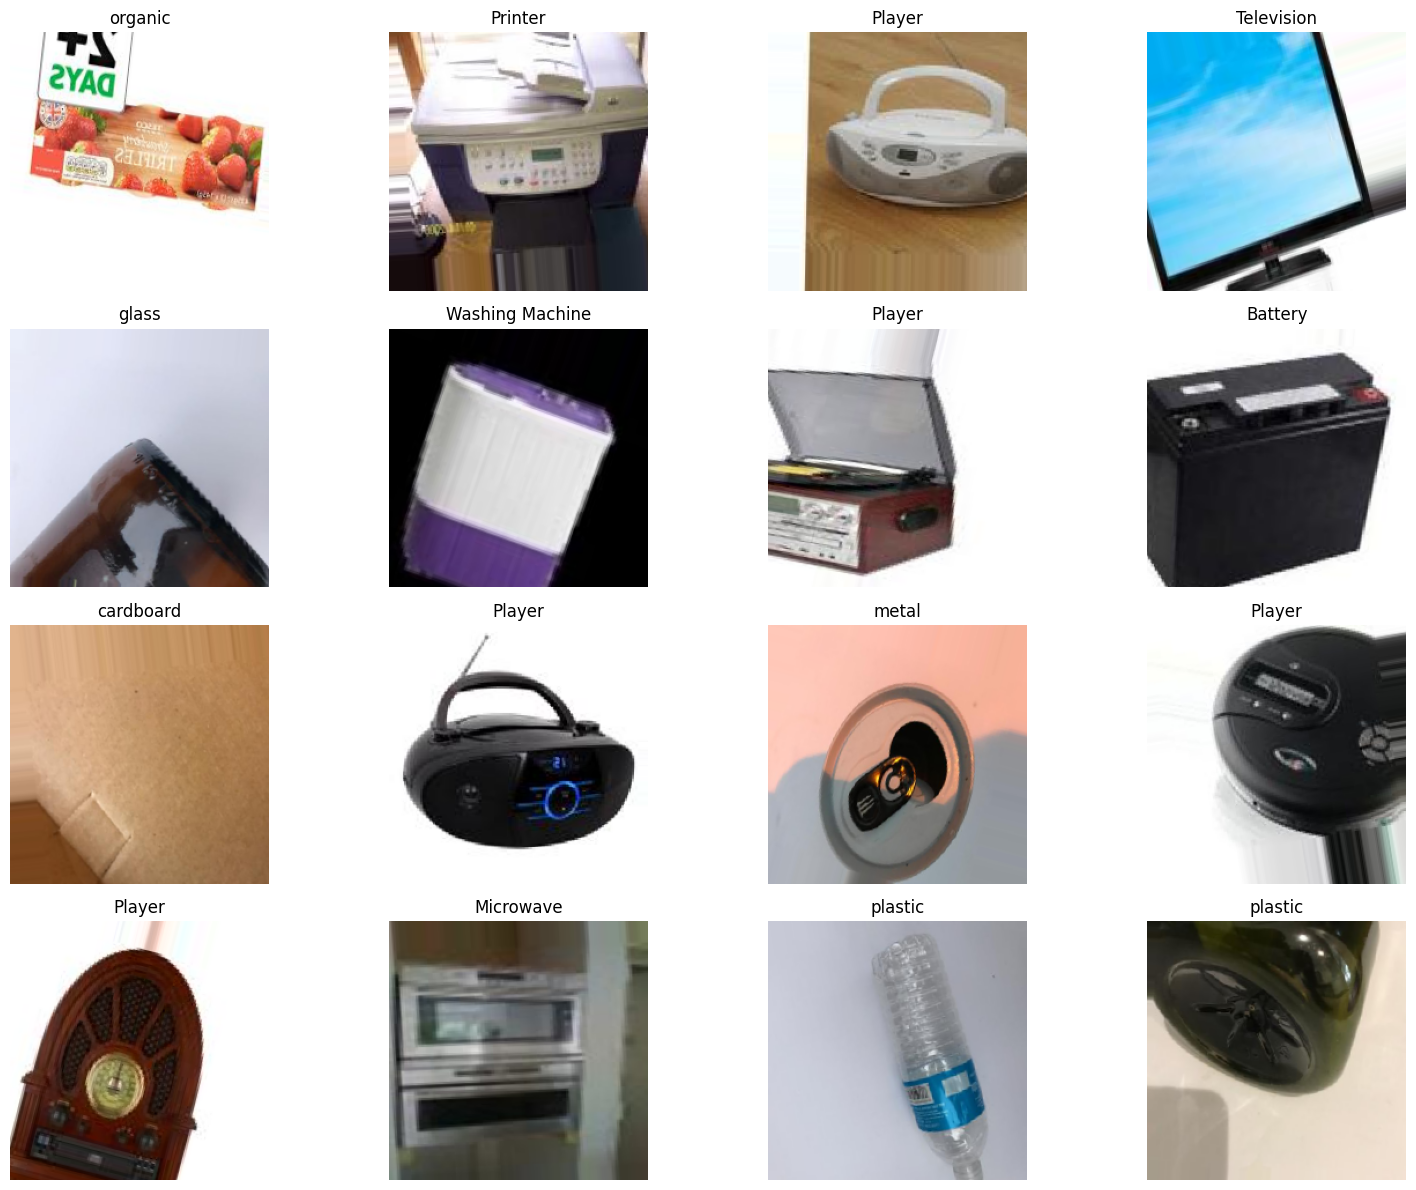

In [21]:
images, labels = next(train_generator)

class_names = list(
    train_generator.class_indices.keys()
)

plt.figure(figsize=(16, 12))

for i in range(min(16, len(images))):

    plt.subplot(4, 4, i + 1)

    plt.imshow(images[i])

    class_index = np.argmax(labels[i])

    plt.title(
        class_names[class_index]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Calculate Class Weights

In [22]:
classes_array = np.unique(train_df["class"])

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes_array,
    y=train_df["class"]
)

class_weights = dict(
    zip(
        train_generator.class_indices.values(),
        class_weights_array
    )
)

print(class_weights)

{0: np.float64(1.000843348091925), 1: np.float64(1.000843348091925), 2: np.float64(1.000843348091925), 3: np.float64(0.9972689075630252), 4: np.float64(1.000843348091925), 5: np.float64(1.000843348091925), 6: np.float64(1.000843348091925), 7: np.float64(1.0117220801364024), 8: np.float64(1.000843348091925), 9: np.float64(0.9972689075630252), 10: np.float64(0.9972689075630252), 11: np.float64(0.9972689075630252), 12: np.float64(0.9972689075630252), 13: np.float64(0.9972689075630252), 14: np.float64(0.9972689075630252), 15: np.float64(0.9972689075630252), 16: np.float64(1.0044435040203132)}


# Build CNN Model

In [23]:
model = keras.Sequential([

    layers.Input(
        shape=(224, 224, 3)
    ),

    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(
        256,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu"
    ),

    layers.Dropout(
        0.5
    ),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

model.summary()

I0000 00:00:1791313554.245199      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791313554.248687      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 17)             │         4,369 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,830,225 (37.50 MB)

 Trainable params: 9,830,225 (37.50 MB)

 Non-trainable params: 0 (0.00 B)

# Compile CNN

In [24]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


# Create Callbacks

In [25]:
callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    ),

    keras.callbacks.ModelCheckpoint(
        "best_waste_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

# Train CNN

In [26]:
EPOCHS = 20

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


2026-10-06 19:06:02.621830: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-06 19:06:02.770049: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  2/149 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.0547 - loss: 3.3273

I0000 00:00:1791313566.023345      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


149/149 ━━━━━━━━━━━━━━━━━━━━ 72s 422ms/step - accuracy: 0.1517 - loss: 2.5980 - val_accuracy: 0.2488 - val_loss: 2.2072 - learning_rate: 0.0010
Epoch 2/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 378ms/step - accuracy: 0.2703 - loss: 2.2210 - val_accuracy: 0.3727 - val_loss: 1.9251 - learning_rate: 0.0010
Epoch 3/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 375ms/step - accuracy: 0.3324 - loss: 2.0007 - val_accuracy: 0.4336 - val_loss: 1.7289 - learning_rate: 0.0010
Epoch 4/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 378ms/step - accuracy: 0.3781 - loss: 1.8451 - val_accuracy: 0.4356 - val_loss: 1.6681 - learning_rate: 0.0010
Epoch 5/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 385ms/step - accuracy: 0.4148 - loss: 1.7363 - val_accuracy: 0.4769 - val_loss: 1.5503 - learning_rate: 0.0010
Epoch 6/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 378ms/step - accuracy: 0.4462 - loss: 1.6570 - val_accuracy: 0.5103 - val_loss: 1.4394 - learning_rate: 0.0010
Epoch 7/20
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 376ms/step - accuracy: 0.4698 - loss:

# Training Accuracy

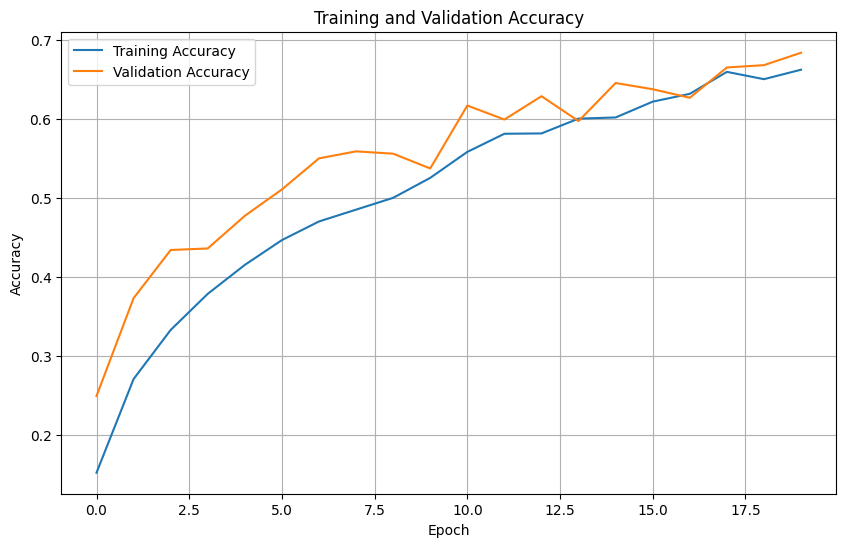

In [27]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()
plt.grid()

plt.show()

# Training Loss

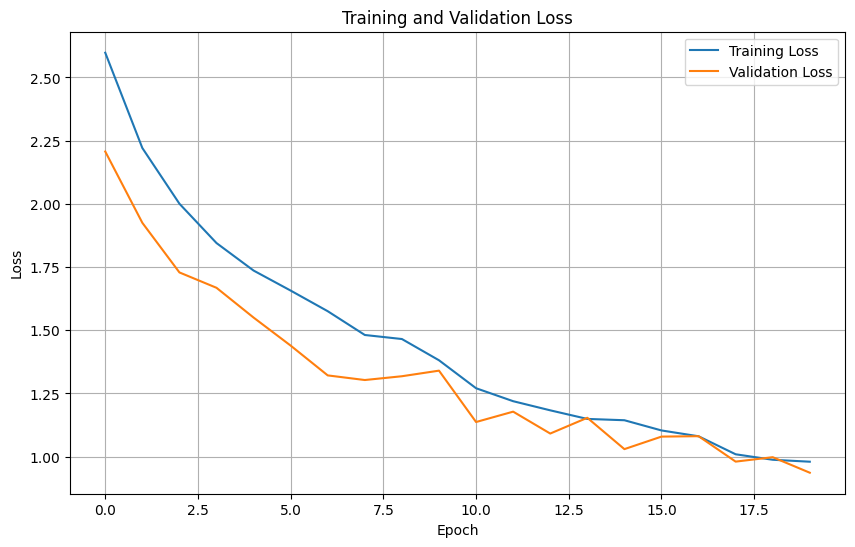

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()
plt.grid()

plt.show()

# Evaluate Test Dataset

In [29]:
test_loss, test_accuracy = model.evaluate(
    test_generator
)

print(
    "Test Loss:",
    test_loss
)

print(
    "Test Accuracy:",
    test_accuracy
)

32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 143ms/step - accuracy: 0.7132 - loss: 0.8617
Test Loss: 0.8617444634437561
Test Accuracy: 0.7131630778312683


# Generate Predictions

In [30]:
test_generator.reset()

predictions = model.predict(
    test_generator
)

predicted_classes = np.argmax(
    predictions,
    axis=1
)

true_classes = test_generator.classes

class_names = list(
    test_generator.class_indices.keys()
)

print("Predictions generated successfully")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step
Predictions generated successfully


# Classification Report

In [31]:
report = classification_report(
    true_classes,
    predicted_classes,
    target_names=class_names
)

print(report)

                 precision    recall  f1-score   support

        Battery       0.68      0.72      0.70        60
       Keyboard       0.95      0.88      0.91        60
      Microwave       0.78      0.63      0.70        60
         Mobile       0.65      0.88      0.75        60
          Mouse       0.66      0.42      0.51        60
            PCB       0.87      0.80      0.83        60
         Player       0.51      0.60      0.55        60
        Printer       0.60      0.55      0.57        60
     Television       0.72      0.69      0.71        59
Washing Machine       0.93      0.83      0.88        60
      cardboard       0.85      0.77      0.81        60
          glass       0.79      0.50      0.61        60
          metal       0.59      0.75      0.66        60
        organic       0.73      0.90      0.81        60
          paper       0.62      0.73      0.67        60
        plastic       0.79      0.63      0.70        60
          trash       0.63    

# Confusion Matrix

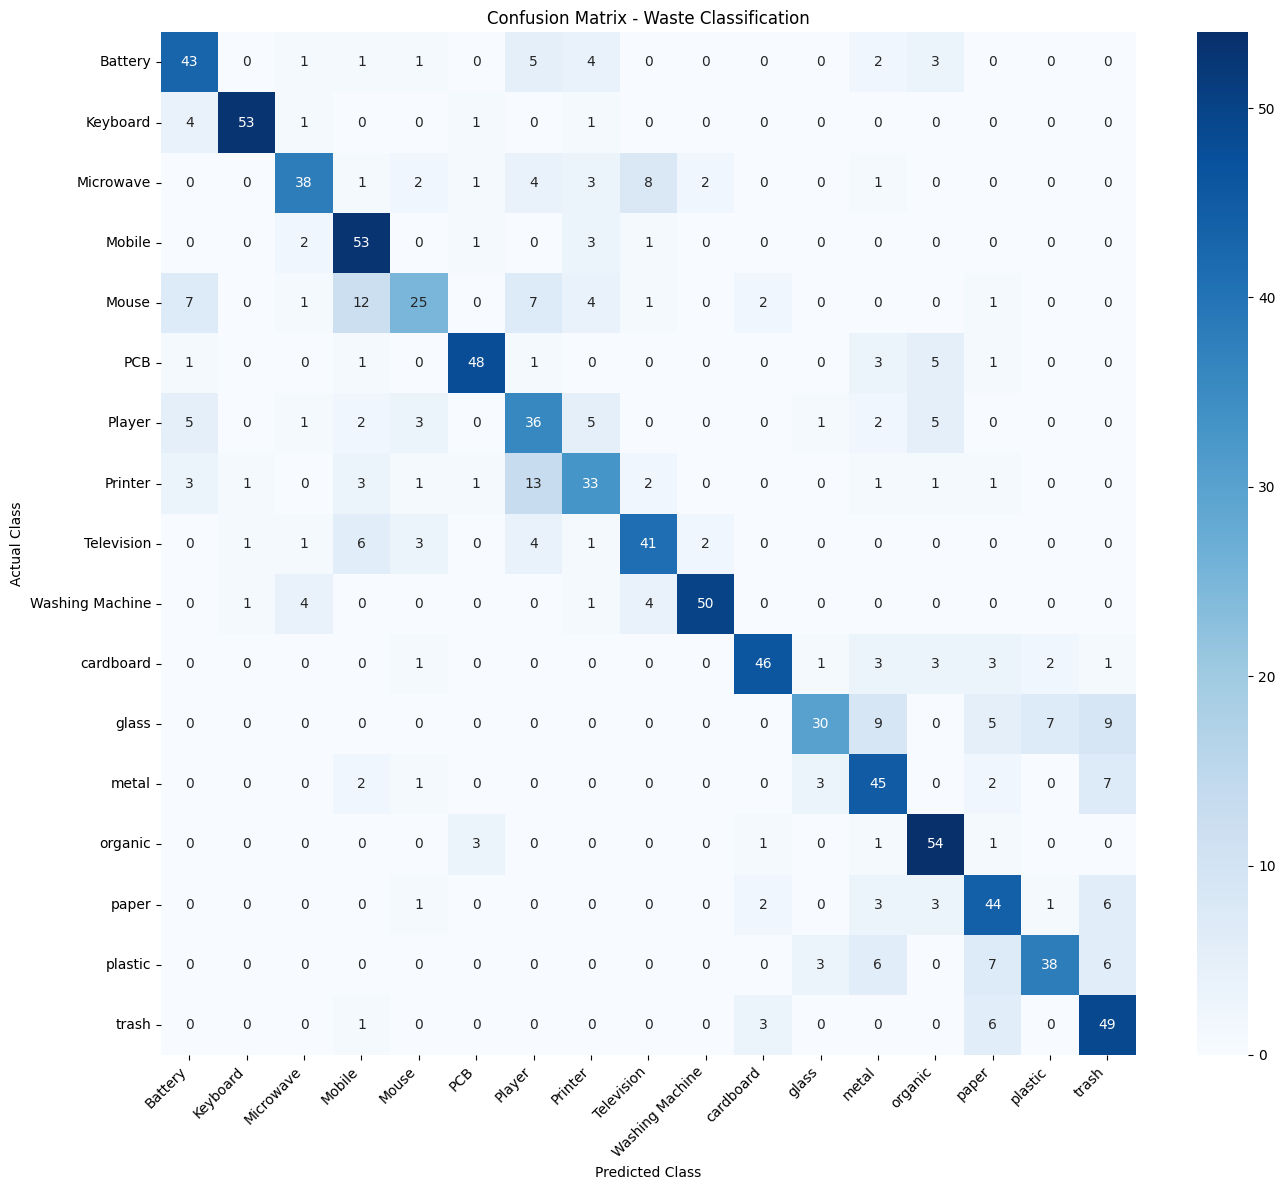

In [32]:
cm = confusion_matrix(
    true_classes,
    predicted_classes
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "Confusion Matrix - Waste Classification"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Overall Perfomance Metrics

In [33]:
accuracy = accuracy_score(
    true_classes,
    predicted_classes
)

precision = precision_score(
    true_classes,
    predicted_classes,
    average="weighted"
)

recall = recall_score(
    true_classes,
    predicted_classes,
    average="weighted"
)

f1 = f1_score(
    true_classes,
    predicted_classes,
    average="weighted"
)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

print(metrics_df)

      Metric     Score
0   Accuracy  0.713163
1  Precision  0.726203
2     Recall  0.713163
3   F1 Score  0.711255


# Performance Graph

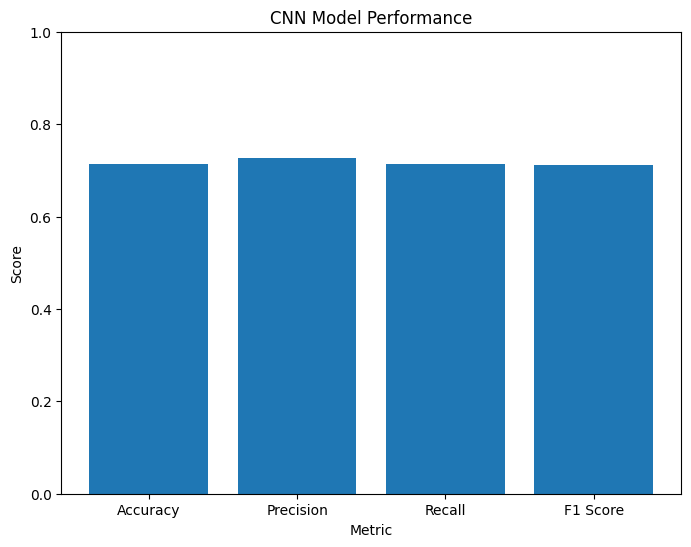

In [34]:
plt.figure(figsize=(8, 6))

plt.bar(
    metrics_df["Metric"],
    metrics_df["Score"]
)

plt.ylim(0, 1)

plt.xlabel("Metric")
plt.ylabel("Score")

plt.title(
    "CNN Model Performance"
)

plt.show()

# Correctly Classified Images

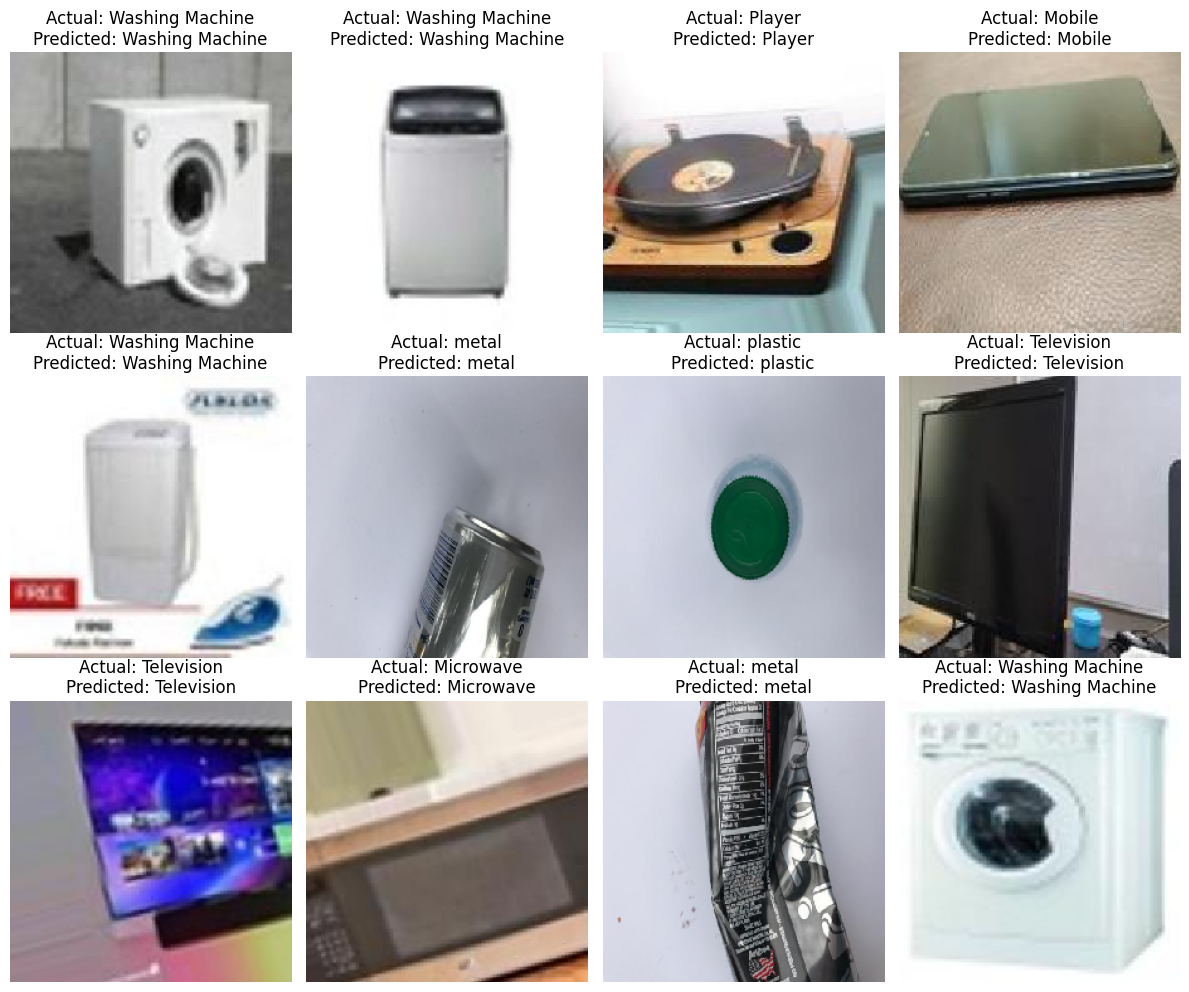

In [35]:
correct_indices = np.where(
    predicted_classes == true_classes
)[0]

sample_indices = np.random.choice(
    correct_indices,
    min(12, len(correct_indices)),
    replace=False
)

plt.figure(figsize=(12, 10))

for i, idx in enumerate(sample_indices):

    image = tf.keras.utils.load_img(
        test_df.iloc[idx]["filepath"],
        target_size=IMG_SIZE
    )

    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    actual = class_names[
        true_classes[idx]
    ]

    predicted = class_names[
        predicted_classes[idx]
    ]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# Misclassified Images

Total Misclassified Images: 292


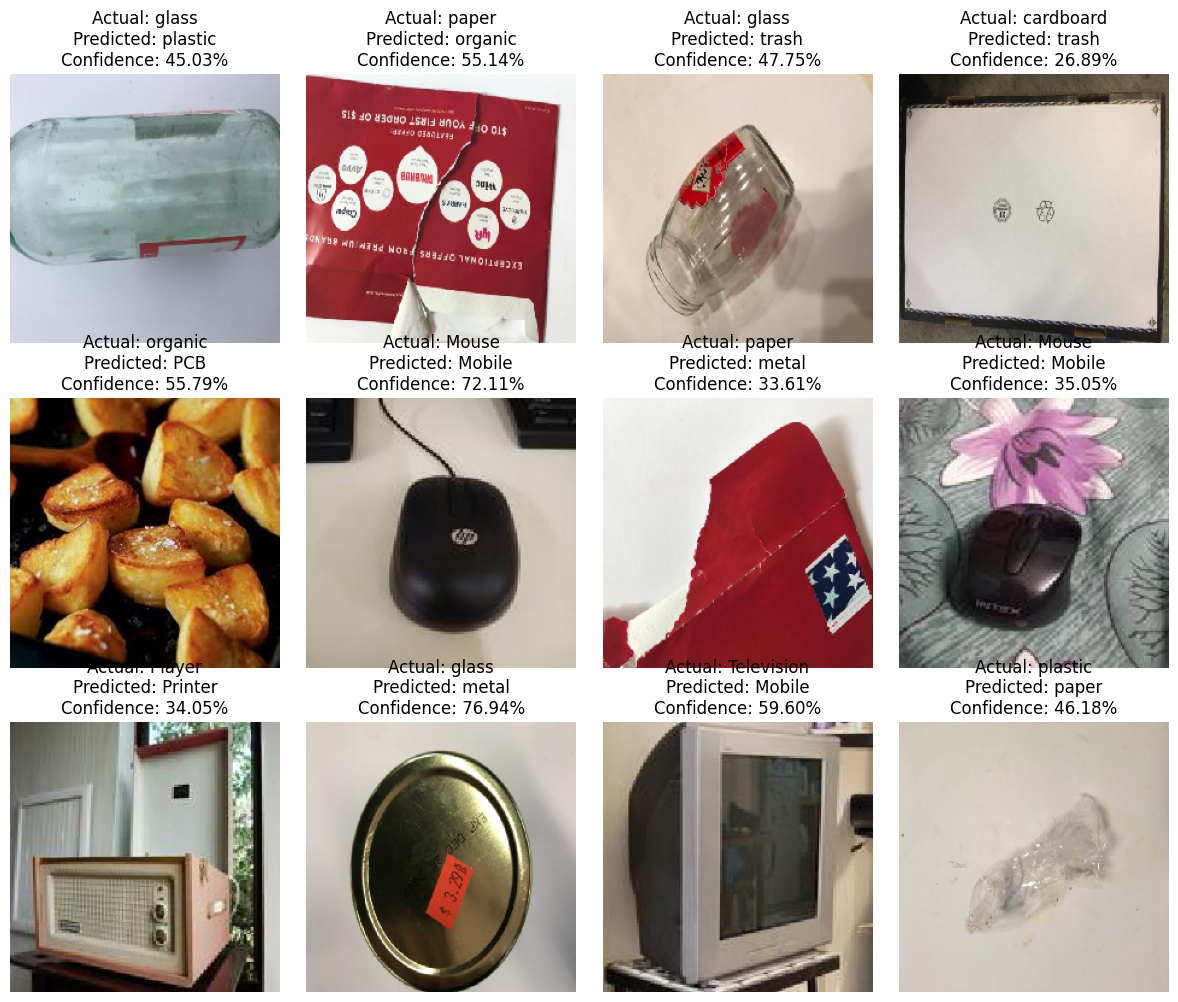

In [36]:
wrong_indices = np.where(
    predicted_classes != true_classes
)[0]

print(
    "Total Misclassified Images:",
    len(wrong_indices)
)

if len(wrong_indices) > 0:

    sample_indices = np.random.choice(
        wrong_indices,
        min(12, len(wrong_indices)),
        replace=False
    )

    plt.figure(figsize=(12, 10))

    for i, idx in enumerate(sample_indices):

        image = tf.keras.utils.load_img(
            test_df.iloc[idx]["filepath"],
            target_size=IMG_SIZE
        )

        plt.subplot(3, 4, i + 1)

        plt.imshow(image)

        actual = class_names[
            true_classes[idx]
        ]

        predicted = class_names[
            predicted_classes[idx]
        ]

        confidence = predictions[
            idx
        ][
            predicted_classes[idx]
        ]

        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence:.2%}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Most Confused Class Pairs

In [37]:
confusion_pairs = []

for i in range(len(class_names)):

    for j in range(len(class_names)):

        if i != j and cm[i, j] > 0:

            confusion_pairs.append({
                "Actual": class_names[i],
                "Predicted": class_names[j],
                "Count": cm[i, j]
            })

confusion_pairs_df = pd.DataFrame(
    confusion_pairs
).sort_values(
    "Count",
    ascending=False
)

print(
    confusion_pairs_df.head(15)
)

        Actual   Predicted  Count
50     Printer      Player     13
25       Mouse      Mobile     12
73       glass       metal      9
76       glass       trash      9
16   Microwave  Television      8
26       Mouse      Player      7
81       metal       trash      7
75       glass     plastic      7
23       Mouse     Battery      7
94     plastic       paper      7
93     plastic       metal      6
57  Television      Mobile      6
98       trash       paper      6
95     plastic       trash      6
91       paper       trash      6


# Save CNN Model

In [38]:
model.save(
    "waste_classification_cnn.keras"
)

print(
    "Model saved successfully"
)

Model saved successfully


# Save Class Names

In [39]:
with open(
    "class_names.json",
    "w"
) as f:

    json.dump(
        class_names,
        f
    )

print(
    "Class names saved successfully"
)

Class names saved successfully


# Load Saved Model

In [40]:
loaded_model = keras.models.load_model(
    "waste_classification_cnn.keras"
)

print(
    "Model loaded successfully"
)

Model loaded successfully


# Single Image Prediction Function

In [41]:
def predict_waste(image_path):

    image = tf.keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image_array = tf.keras.utils.img_to_array(
        image
    )

    image_array = image_array / 255.0

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    prediction = loaded_model.predict(
        image_array,
        verbose=0
    )

    predicted_index = np.argmax(
        prediction[0]
    )

    predicted_class = class_names[
        predicted_index
    ]

    confidence = prediction[0][
        predicted_index
    ]

    return predicted_class, confidence

# Test Single Image

In [42]:
image_path = test_df.iloc[0]["filepath"]

predicted_class, confidence = predict_waste(
    image_path
)

print(
    "Predicted Class:",
    predicted_class
)

print(
    "Confidence:",
    f"{confidence:.2%}"
)

Predicted Class: plastic
Confidence: 86.01%


# Display Prediction

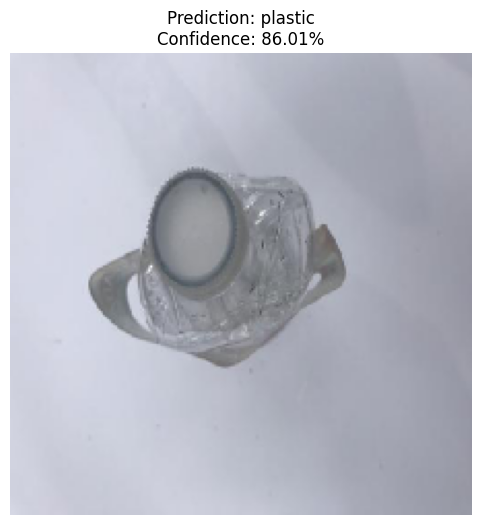

In [43]:
image = tf.keras.utils.load_img(
    image_path,
    target_size=IMG_SIZE
)

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)

plt.axis("off")

plt.show()

# Top 3 Predictions

In [44]:
image = tf.keras.utils.load_img(
    image_path,
    target_size=IMG_SIZE
)

image_array = tf.keras.utils.img_to_array(
    image
)

image_array = image_array / 255.0

image_array = np.expand_dims(
    image_array,
    axis=0
)

prediction = loaded_model.predict(
    image_array,
    verbose=0
)[0]

top_indices = np.argsort(
    prediction
)[-3:][::-1]

for index in top_indices:

    print(
        class_names[index],
        "->",
        f"{prediction[index]:.2%}"
    )

plastic -> 86.01%
glass -> 13.32%
metal -> 0.50%


# Final Model Summary

In [45]:
print("========== FINAL RESULTS ==========")

print(
    "Number of Classes:",
    NUM_CLASSES
)

print(
    "Training Images:",
    len(train_df)
)

print(
    "Validation Images:",
    len(val_df)
)

print(
    "Testing Images:",
    len(test_df)
)

print(
    "Test Accuracy:",
    f"{accuracy:.4f}"
)

print(
    "Weighted Precision:",
    f"{precision:.4f}"
)

print(
    "Weighted Recall:",
    f"{recall:.4f}"
)

print(
    "Weighted F1 Score:",
    f"{f1:.4f}"
)

========== FINAL RESULTS ==========
Number of Classes: 17
Training Images: 4747
Validation Images: 1017
Testing Images: 1018
Test Accuracy: 0.7132
Weighted Precision: 0.7262
Weighted Recall: 0.7132
Weighted F1 Score: 0.7113


# Live Predictions

In [46]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Choose Image"
)

display(upload)

def predict_uploaded_image(change):
    if not upload.value:
        return

    uploaded_file = list(upload.value.values())[0]
    image_bytes = uploaded_file["content"]

    img = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    img = tf.image.resize(img, IMG_SIZE)
    img_array = tf.cast(img, tf.float32) / 255.0
    img_array = tf.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0]

    top_indices = np.argsort(prediction)[::-1][:3]

    plt.figure(figsize=(7, 7))
    plt.imshow(img.numpy().astype("uint8"))
    plt.axis("off")

    plt.title(
        f"Prediction: {class_names[top_indices[0]]}\n"
        f"Confidence: {prediction[top_indices[0]] * 100:.2f}%"
    )

    plt.show()

    print("\nTop 3 Predictions:")
    for i, idx in enumerate(top_indices, 1):
        print(
            f"{i}. {class_names[idx]} - "
            f"{prediction[idx] * 100:.2f}%"
        )

upload.observe(predict_uploaded_image, names="value")

FileUpload(value=(), accept='image/*', description='Choose Image')